# Step 1: Problem Understanding 

### 1.1 Business problem

A subscription-based company is experiencing customer churn. Management wants to identify customers who are likely to leave so that the retention team can intervene before they churn.

### 1.2 Business objective

The model should help the retention team:

1. Identify customers who may leave.

2. Understand customer characteristics associated with churn.

3. Prioritize customers for retention interventions.

4. Evaluate predictions on unseen data.

# Step 2: Import and Initial Dataset Inspection

In [258]:
# Load the CSV using pandas.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Supervised_Learning_Messy_Customer_Churn.csv")

df.head()


,Customer_ID,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Churn
0,CUST-1020,22.0,23800.0,11.0,62.96,7.0,20.4,5.0,MONTHLY,Bank Transfer,North,Standard,Yes
1,CUST-1043,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,Monthly,Bank Transfer,South,Basic,Yes
2,CUST-1157,55.0,NaN,49.0,92.85,3.0,21.6,1.0,Monthly,UPI,West,Basic,Yes
3,CUST-1112,36.0,80000.0,9.0,85.67,0.0,34.3,9.0,Monthly,UPI,South,Standard,Yes
4,CUST-1149,41.0,95700.0,51.0,60.77,1.0,23.7,9.0,Monthly,Debit Card,West,Premium,Yes


In [259]:
# Inspect shape, data types, sample records, descriptive statistics, and target distribution. 

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1]) 

Number of Rows: 184
Number of Columns: 13


In [260]:
df.head()

,Customer_ID,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Churn
0,CUST-1020,22.0,23800.0,11.0,62.96,7.0,20.4,5.0,MONTHLY,Bank Transfer,North,Standard,Yes
1,CUST-1043,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,Monthly,Bank Transfer,South,Basic,Yes
2,CUST-1157,55.0,NaN,49.0,92.85,3.0,21.6,1.0,Monthly,UPI,West,Basic,Yes
3,CUST-1112,36.0,80000.0,9.0,85.67,0.0,34.3,9.0,Monthly,UPI,South,Standard,Yes
4,CUST-1149,41.0,95700.0,51.0,60.77,1.0,23.7,9.0,Monthly,Debit Card,West,Premium,Yes


In [261]:
df.tail()

,Customer_ID,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Churn
179,CUST-1107,55.0,54100.0,68.0,99.59,6.0,21.5,8.0,1 Year,Bank Transfer,East,Basic,Yes
180,CUST-1015,19.0,63000.0,NaN,64.24,1.0,13.0,7.0,Monthly,Credit Card,south,Premium,Yes
181,CUST-1093,29.0,45300.0,69.0,67.48,1.0,10.6,6.0,Monthly,Debit Card,East,Standard,No
182,CUST-1180,63.0,47100.0,45.0,65.58,0.0,11.3,1.0,Monthly,UPI,East,Standard,Yes
183,CUST-1103,NaN,48300.0,13.0,94.69,0.0,16.8,1.0,2 Year,Bank Transfer,West,Standard,No


In [262]:
print("All the columns:- \n \t", df.columns.tolist()) 
print("-" * 50) 
print(" " * 50) 
print( "Categorical columns:- \n \t" , df.select_dtypes(include = ["category", "object"]).columns.tolist())
print("-" * 50) 
print(" " * 50) 
print( "Numerical columns:- \n \t" , df.select_dtypes(include = ["number"]).columns.tolist()) 
print("-" * 50) 
print(" " * 50) 
print(" " * 50) 

All the columns:- 
 	 ['Customer_ID', 'Age', 'Annual_Income', 'Tenure_Months', 'Monthly_Charges', 'Support_Calls_Last_3M', 'Data_Usage_GB', 'Satisfaction_Score', 'Contract_Type', 'Payment_Method', 'Region', 'Plan_Type', 'Churn']
--------------------------------------------------
                                                  
Categorical columns:- 
 	 ['Customer_ID', 'Annual_Income', 'Contract_Type', 'Payment_Method', 'Region', 'Plan_Type', 'Churn']
--------------------------------------------------
                                                  
Numerical columns:- 
 	 ['Age', 'Tenure_Months', 'Monthly_Charges', 'Support_Calls_Last_3M', 'Data_Usage_GB', 'Satisfaction_Score']
--------------------------------------------------
                                                  
                                                  


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_17840\1649015166.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print( "Categorical columns:- \n \t" , df.select_dtypes(include = ["category", "object"]).columns.tolist())


In [263]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 184 entries, 0 to 183
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            184 non-null    str    
 1   Age                    176 non-null    float64
 2   Annual_Income          173 non-null    str    
 3   Tenure_Months          177 non-null    float64
 4   Monthly_Charges        178 non-null    float64
 5   Support_Calls_Last_3M  179 non-null    float64
 6   Data_Usage_GB          178 non-null    float64
 7   Satisfaction_Score     178 non-null    float64
 8   Contract_Type          184 non-null    str    
 9   Payment_Method         184 non-null    str    
 10  Region                 184 non-null    str    
 11  Plan_Type              184 non-null    str    
 12  Churn                  184 non-null    str    
dtypes: float64(6), str(7)
memory usage: 27.0 KB


In [264]:
df.describe()

,Age,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score
count,176.000000,177.000000,178.000000,179.000000,178.000000,178.000000
mean,36.164773,39.395480,80.205899,3.217877,17.806180,5.803371
std,12.865951,21.545185,74.179370,2.577455,9.245516,2.947869
min,-5.000000,1.000000,0.000000,0.000000,-10.000000,1.000000
25%,29.000000,25.000000,57.885000,2.000000,11.600000,4.000000
50%,36.000000,38.000000,73.565000,3.000000,18.200000,6.000000
75%,41.000000,55.000000,90.280000,4.000000,24.200000,8.000000
max,145.000000,150.000000,999.000000,30.000000,44.000000,15.000000


In [265]:
df.describe(include="object")

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_17840\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Customer_ID,Annual_Income,Contract_Type,Payment_Method,Region,Plan_Type,Churn
count,184,173,184,184,184,184,184
unique,180,156,8,9,8,6,2
top,CUST-1043,76600.0,Monthly,Bank Transfer,South,Standard,Yes
freq,2,4,104,48,50,93,97


Churn
Yes    97
No     87
Name: count, dtype: int64
---------------------------------------------
Churn
Yes    52.72
No     47.28
Name: proportion, dtype: float64
---------------------------------------------


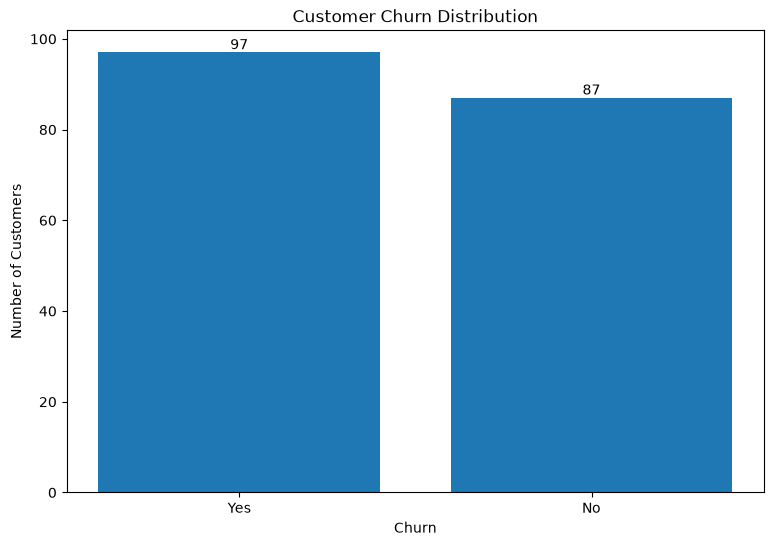

In [266]:
# Inspect the target variable ( churn )

print(df["Churn"].value_counts())
print("---------------------------------------------") 
print(df["Churn"].value_counts(normalize=True).mul(100).round(2))
print("---------------------------------------------") 
fig, ax = plt.subplots(figsize=(9, 6))
churn_counts = df["Churn"].value_counts()

bars = ax.bar(
    churn_counts.index,
    churn_counts.values
)

ax.bar_label(bars)
ax.set_xlabel("Churn")
ax.set_ylabel("Number of Customers")
ax.set_title("Customer Churn Distribution")
plt.show()

In [267]:
# Check missing values and duplicate records 

missing_values = df.isnull().sum()

print(missing_values)

print("-------------------------------------------------") 

missing_percentage = (
    df.isnull().sum() / len(df) * 100
).round(2)

print(missing_percentage)

Customer_ID               0
Age                       8
Annual_Income            11
Tenure_Months             7
Monthly_Charges           6
Support_Calls_Last_3M     5
Data_Usage_GB             6
Satisfaction_Score        6
Contract_Type             0
Payment_Method            0
Region                    0
Plan_Type                 0
Churn                     0
dtype: int64
-------------------------------------------------
Customer_ID              0.00
Age                      4.35
Annual_Income            5.98
Tenure_Months            3.80
Monthly_Charges          3.26
Support_Calls_Last_3M    2.72
Data_Usage_GB            3.26
Satisfaction_Score       3.26
Contract_Type            0.00
Payment_Method           0.00
Region                   0.00
Plan_Type                0.00
Churn                    0.00
dtype: float64


In [268]:
# Check duplicate records 

print("Duplicate Rows:", df.duplicated().sum())
print("---------------------------------------------------------------") 
print("Duplicate Customer IDs:", df["Customer_ID"].duplicated().sum())

Duplicate Rows: 4
---------------------------------------------------------------
Duplicate Customer IDs: 4


In [269]:
# Inspect categorical values 

categorical_columns = df.select_dtypes(
    include="object"
).columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


Customer_ID:
<ArrowStringArray>
['CUST-1020', 'CUST-1043', 'CUST-1157', 'CUST-1112', 'CUST-1149', 'CUST-1016',
 'CUST-1025', 'CUST-1069', 'CUST-1118', 'CUST-1099',
 ...
 'CUST-1088', 'CUST-1075', 'CUST-1122', 'CUST-1021', 'CUST-1072', 'CUST-1107',
 'CUST-1015', 'CUST-1093', 'CUST-1180', 'CUST-1103']
Length: 180, dtype: str

Annual_Income:
<ArrowStringArray>
[ '23800.0',  '69400.0',        nan,  '80000.0',  '95700.0',  '88000.0',
  '49100.0',  '69200.0',  '43300.0',  '59800.0',
 ...
  '54200.0',  '37900.0',  '71300.0',  '79200.0', '100400.0',  '54100.0',
  '63000.0',  '45300.0',  '47100.0',  '48300.0']
Length: 157, dtype: str

Contract_Type:
<ArrowStringArray>
['MONTHLY', 'Monthly', '1 Year', '2 Year', '2-Year', '1 year', 'monthly', '?']
Length: 8, dtype: str

Payment_Method:
<ArrowStringArray>
['Bank Transfer',           'UPI',    'Debit Card',   'Credit Card',
             '?', 'bank transfer',           'upi',       'Unknown',
   'Credit card']
Length: 9, dtype: str

Region:
<ArrowS

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_17840\1596224560.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [270]:
# Inspect suspicious numerical values 

print(df["Annual_Income"].unique())

<ArrowStringArray>
[ '23800.0',  '69400.0',        nan,  '80000.0',  '95700.0',  '88000.0',
  '49100.0',  '69200.0',  '43300.0',  '59800.0',
 ...
  '54200.0',  '37900.0',  '71300.0',  '79200.0', '100400.0',  '54100.0',
  '63000.0',  '45300.0',  '47100.0',  '48300.0']
Length: 157, dtype: str


In [271]:
# Check numerical minimum and maximum 

numeric_columns = df.select_dtypes(
    include="number"
).columns

for column in numeric_columns:
    print(
        f"{column}: "
        f"Min = {df[column].min()}, "
        f"Max = {df[column].max()}"
    )

Age: Min = -5.0, Max = 145.0
Tenure_Months: Min = 1.0, Max = 150.0
Monthly_Charges: Min = 0.0, Max = 999.0
Support_Calls_Last_3M: Min = 0.0, Max = 30.0
Data_Usage_GB: Min = -10.0, Max = 44.0
Satisfaction_Score: Min = 1.0, Max = 15.0


In [272]:
identifier_columns = ["Customer_ID"]

target_column = "Churn"

print("Identifier Columns:", identifier_columns)
print("Target Column:", target_column)

Identifier Columns: ['Customer_ID']
Target Column: Churn


# Step 3: Data Cleaning

In [273]:
# Create a working copy 

df_clean = df.copy()

print("Original Shape:", df.shape)
print("Working Shape:", df_clean.shape)

Original Shape: (184, 13)
Working Shape: (184, 13)


In [274]:
# Replace placeholder values 

df_clean.replace(
    to_replace=r"^\s*(NA|N/A|\?|)$",             # A regular expression that identifies placeholders.
    value=np.nan,                                # Replaces matched values with a proper missing value.
    regex=True,                                  # Tells Pandas to interpret the pattern as a regular expression.
    inplace=True                                 # Modifies df_clean directly.
)

print("Placeholder values converted to NaN.")

Placeholder values converted to NaN.


In [275]:
# Check missing values 

missing_summary = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

print(missing_summary.sort_values(
    by="Missing_Count",
    ascending=False
))

print("-" * 50)
print(
    "Rows with Missing Values:",
    df_clean.isnull().any(axis=1).sum() )

                       Missing_Count  Missing_Percentage
Annual_Income                     12                6.52
Age                                8                4.35
Tenure_Months                      7                3.80
Monthly_Charges                    6                3.26
Data_Usage_GB                      6                3.26
Satisfaction_Score                 6                3.26
Support_Calls_Last_3M              5                2.72
Payment_Method                     1                0.54
Contract_Type                      1                0.54
Region                             1                0.54
Customer_ID                        0                0.00
Plan_Type                          0                0.00
Churn                              0                0.00
--------------------------------------------------
Rows with Missing Values: 44


In [276]:
# Duplicate Records 

# Check exact duplicate records 

print("Exact Duplicate Rows:", df_clean.duplicated().sum()) 

duplicates = df_clean[
    df_clean.duplicated(keep=False)
]

duplicates.sort_values("Customer_ID")

Exact Duplicate Rows: 4


,Customer_ID,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Churn
132,CUST-1008,44.0,43400.0,60.0,95.26,2.0,26.9,1.0,Monthly,Debit Card,South,Basic,Yes
154,CUST-1008,44.0,43400.0,60.0,95.26,2.0,26.9,1.0,Monthly,Debit Card,South,Basic,Yes
1,CUST-1043,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,Monthly,Bank Transfer,South,Basic,Yes
119,CUST-1043,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,Monthly,Bank Transfer,South,Basic,Yes
46,CUST-1110,35.0,29800.0,72.0,115.28,2.0,18.9,5.0,1 Year,Bank Transfer,West,Premium,Yes
71,CUST-1110,35.0,29800.0,72.0,115.28,2.0,18.9,5.0,1 Year,Bank Transfer,West,Premium,Yes
169,CUST-1152,39.0,76600.0,25.0,90.28,4.0,8.4,8.0,Monthly,Bank Transfer,West,Premium,No
176,CUST-1152,39.0,76600.0,25.0,90.28,4.0,8.4,8.0,Monthly,Bank Transfer,West,Premium,No


In [277]:
# Check repeated Customer IDs

print(
    "Duplicate Customer IDs:",
    df_clean["Customer_ID"].duplicated().sum()
)

repeated_customers = df_clean[
    df_clean["Customer_ID"].duplicated(keep=False)
].sort_values("Customer_ID")

repeated_customers

Duplicate Customer IDs: 4


,Customer_ID,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Churn
132,CUST-1008,44.0,43400.0,60.0,95.26,2.0,26.9,1.0,Monthly,Debit Card,South,Basic,Yes
154,CUST-1008,44.0,43400.0,60.0,95.26,2.0,26.9,1.0,Monthly,Debit Card,South,Basic,Yes
1,CUST-1043,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,Monthly,Bank Transfer,South,Basic,Yes
119,CUST-1043,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,Monthly,Bank Transfer,South,Basic,Yes
46,CUST-1110,35.0,29800.0,72.0,115.28,2.0,18.9,5.0,1 Year,Bank Transfer,West,Premium,Yes
71,CUST-1110,35.0,29800.0,72.0,115.28,2.0,18.9,5.0,1 Year,Bank Transfer,West,Premium,Yes
169,CUST-1152,39.0,76600.0,25.0,90.28,4.0,8.4,8.0,Monthly,Bank Transfer,West,Premium,No
176,CUST-1152,39.0,76600.0,25.0,90.28,4.0,8.4,8.0,Monthly,Bank Transfer,West,Premium,No


In [278]:
df_clean = df_clean.drop_duplicates(keep="first")

print("Dataset Shape:", df_clean.shape)
print("Exact Duplicate Rows:", df_clean.duplicated().sum())

Dataset Shape: (180, 13)
Exact Duplicate Rows: 0


In [279]:
# Check categorical inconsistencies 

cat_cols = [
    "Contract_Type",
    "Payment_Method",
    "Region",
    "Plan_Type",
    "Churn"
]

for col in cat_cols:
    print(f"\n{col}:")
    print(df_clean[col].value_counts(dropna=False))


Contract_Type:
Contract_Type
Monthly    101
1 Year      51
2 Year      23
MONTHLY      1
2-Year       1
1 year       1
monthly      1
NaN          1
Name: count, dtype: int64

Payment_Method:
Payment_Method
UPI              46
Bank Transfer    45
Credit Card      43
Debit Card       41
NaN               1
bank transfer     1
upi               1
Unknown           1
Credit card       1
Name: count, dtype: int64

Region:
Region
North     49
South     48
West      45
East      34
west       1
NORTH      1
NaN        1
south      1
Name: count, dtype: int64

Plan_Type:
Plan_Type
Standard     93
Basic        46
Premium      38
basic         1
premium       1
STANDARD      1
Name: count, dtype: int64

Churn:
Churn
Yes    94
No     86
Name: count, dtype: int64


In [280]:
# Checking and handling categorical inconsistencies 

# Remove leading and trailing spaces
cat_cols = [
    "Contract_Type",
    "Payment_Method",
    "Region",
    "Plan_Type",
    "Churn"
]

for col in cat_cols:
    df_clean[col] = df_clean[col].str.strip()

# Standardize Contract_Type
df_clean["Contract_Type"] = df_clean["Contract_Type"].replace({
    "MONTHLY": "Monthly",
    "monthly": "Monthly",
    "1 year": "1 Year",
    "2-Year": "2 Year"
})

# Standardize Payment_Method
df_clean["Payment_Method"] = df_clean["Payment_Method"].replace({
    "bank transfer": "Bank Transfer",
    "upi": "UPI",
    "Credit card": "Credit Card",
    "Unknown": np.nan
}) 

print(df_clean["Contract_Type"].value_counts(dropna=False))
print("----------------------------------------------------")
print(df_clean["Payment_Method"].value_counts(dropna=False))
print("----------------------------------------------------")

Contract_Type
Monthly    103
1 Year      52
2 Year      24
NaN          1
Name: count, dtype: int64
----------------------------------------------------
Payment_Method
UPI              47
Bank Transfer    46
Credit Card      44
Debit Card       41
NaN               2
Name: count, dtype: int64
----------------------------------------------------


In [281]:
# Standardize Region values
df_clean["Region"] = df_clean["Region"].str.strip().str.title()

# Verify
print(df_clean["Region"].value_counts(dropna=False))

Region
North    50
South    49
West     46
East     34
NaN       1
Name: count, dtype: int64


In [282]:
# Standardize Plan_Type values
df_clean["Plan_Type"] = df_clean["Plan_Type"].str.strip().str.title()

# Verify
print(df_clean["Plan_Type"].value_counts(dropna=False))

Plan_Type
Standard    94
Basic       47
Premium     39
Name: count, dtype: int64


In [283]:
# Verify target labels
print(df_clean["Churn"].value_counts(dropna=False))
print("\nUnique values:", df_clean["Churn"].unique())

Churn
Yes    94
No     86
Name: count, dtype: int64

Unique values: <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str


In [284]:
# Numerical Data Cleaning 

# Annual_Income 

print("Data Type:", df_clean["Annual_Income"].dtype)

print("\nUnique Values:")
print(df_clean["Annual_Income"].value_counts(dropna=False).head(20))

Data Type: str

Unique Values:
Annual_Income
NaN         12
76600.0      3
76800.0      2
64700.0      2
45700.0      2
67400.0      2
78200.0      2
50800.0      2
100000.0     2
53000.0      2
59300.0      2
62300.0      2
75100.0      2
23800.0      1
69400.0      1
80000.0      1
95700.0      1
88000.0      1
49100.0      1
69200.0      1
Name: count, dtype: int64


In [285]:
# Convert Annual_Income from string to numeric

df_clean["Annual_Income"] = pd.to_numeric(
    df_clean["Annual_Income"],
    errors="coerce"
)

# Verify data type
print("Data Type:", df_clean["Annual_Income"].dtype)

# Verify missing values
print("Missing Values:", df_clean["Annual_Income"].isna().sum())

# Verify numerical summary
print("\nStatistical Summary:")
print(df_clean["Annual_Income"].describe())

Data Type: float64
Missing Values: 12

Statistical Summary:
count    1.680000e+02
mean     1.234518e+05
std      7.669285e+05
min     -1.200000e+04
25%      4.900000e+04
50%      6.440000e+04
75%      7.820000e+04
max      9.999999e+06
Name: Annual_Income, dtype: float64


In [286]:
# Identify suspicious income records

# Inspect negative income values
print("Negative Annual Income:")

display(
    df_clean[df_clean["Annual_Income"] < 0][
        ["Customer_ID", "Annual_Income", "Churn"]
    ]
)

# Inspect the 10 highest income values
print("\nTop 10 Annual Income Values:")
display(
    df_clean.nlargest(10, "Annual_Income")[
        ["Customer_ID", "Annual_Income", "Churn"]
    ]
)

Negative Annual Income:


,Customer_ID,Annual_Income,Churn
95,CUST-1143,-11500.0,No
112,CUST-1062,-12000.0,Yes



Top 10 Annual Income Values:


,Customer_ID,Annual_Income,Churn
96,CUST-1026,9999999.0,No
44,CUST-1148,120900.0,Yes
61,CUST-1177,116500.0,Yes
163,CUST-1158,110200.0,Yes
102,CUST-1040,109500.0,Yes
136,CUST-1162,108100.0,Yes
82,CUST-1011,107900.0,No
161,CUST-1130,107100.0,No
20,CUST-1165,106900.0,Yes
54,CUST-1047,104900.0,No


In [287]:
# Replace invalid Annual_Income values with NaN

df_clean.loc[
    df_clean["Annual_Income"] < 0,
    "Annual_Income"
] = np.nan

df_clean.loc[
    df_clean["Annual_Income"] == 9999999,
    "Annual_Income"
] = np.nan

# Verify
print("Missing Annual Income:", df_clean["Annual_Income"].isna().sum())

print("\nUpdated Summary:")
print(df_clean["Annual_Income"].describe())

Missing Annual Income: 15

Updated Summary:
count       165.000000
mean      65232.727273
std       22623.916666
min        8600.000000
25%       49700.000000
50%       64700.000000
75%       78200.000000
max      120900.000000
Name: Annual_Income, dtype: float64


In [288]:
# Handling numerical column - Age 

print("Age Summary:")
print(df_clean["Age"].describe())

print("\nNegative Ages:")
display(
    df_clean[df_clean["Age"] < 0][
        ["Customer_ID", "Age", "Churn"]
    ]
)

print("\nAges Above 100:")
display(
    df_clean[df_clean["Age"] > 100][
        ["Customer_ID", "Age", "Churn"]
    ]
)

Age Summary:
count    172.000000
mean      36.116279
std       12.999252
min       -5.000000
25%       29.000000
50%       36.000000
75%       41.000000
max      145.000000
Name: Age, dtype: float64

Negative Ages:


,Customer_ID,Age,Churn
144,CUST-1018,-5.0,Yes



Ages Above 100:


,Customer_ID,Age,Churn
127,CUST-1004,145.0,No


In [289]:
# Replace negative ages with NaN
df_clean.loc[
    df_clean["Age"] < 0,
    "Age"
] = np.nan

# Replace ages above 100 with NaN
df_clean.loc[
    df_clean["Age"] > 100,
    "Age"
] = np.nan

# Verify
print("Missing Age Values:", df_clean["Age"].isna().sum())

print("\nUpdated Age Summary:")
print(df_clean["Age"].describe())

Missing Age Values: 10

Updated Age Summary:
count    170.000000
mean      35.717647
std        9.521836
min       10.000000
25%       29.000000
50%       36.000000
75%       41.000000
max       63.000000
Name: Age, dtype: float64


In [290]:
# Handling numerical column - Tenure_Months 

# Inspect Tenure_Months

print(df_clean["Tenure_Months"].describe())

print("\nMissing Values:")
print(df_clean["Tenure_Months"].isna().sum())

print("\nUnique Values:")
print(sorted(df_clean["Tenure_Months"].dropna().unique()))


count    173.000000
mean      39.300578
std       21.499104
min        1.000000
25%       25.000000
50%       38.000000
75%       54.000000
max      150.000000
Name: Tenure_Months, dtype: float64

Missing Values:
7

Unique Values:
[np.float64(1.0), np.float64(2.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(17.0), np.float64(18.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(29.0), np.float64(30.0), np.float64(31.0), np.float64(32.0), np.float64(33.0), np.float64(34.0), np.float64(35.0), np.float64(36.0), np.float64(37.0), np.float64(38.0), np.float64(39.0), np.float64(40.0), np.float64(41.0), np.float64(42.0), np.float64(43.0), np.float64(45.0), np.float64(46.0), np.float64(47.0), np

In [291]:
# Inspect unusually high tenure values

print(
    df_clean.loc[
        df_clean["Tenure_Months"] > 72,
        ["Customer_ID", "Tenure_Months", "Contract_Type", "Churn"]
    ]
)


# Check zero or negative tenure

print(
    df_clean.loc[
        df_clean["Tenure_Months"] <= 0,
        ["Customer_ID", "Tenure_Months", "Churn"]
    ]
)

   Customer_ID  Tenure_Months Contract_Type Churn
40   CUST-1013          150.0        1 Year    No
Empty DataFrame
Columns: [Customer_ID, Tenure_Months, Churn]
Index: []


In [292]:
print("Missing Tenure Values:",
      df_clean["Tenure_Months"].isna().sum())

print(df_clean["Tenure_Months"].describe())

Missing Tenure Values: 7
count    173.000000
mean      39.300578
std       21.499104
min        1.000000
25%       25.000000
50%       38.000000
75%       54.000000
max      150.000000
Name: Tenure_Months, dtype: float64


In [293]:
# Handling numerical column - Monthly_Charges 

# Inspect Monthly_Charges

print(df_clean["Monthly_Charges"].describe())

print("\nMissing Values:")
print(df_clean["Monthly_Charges"].isna().sum())

print("\nHighest Monthly Charges:")
print(
    df_clean.nlargest(10, "Monthly_Charges")[
        ["Customer_ID", "Monthly_Charges", "Plan_Type", "Contract_Type", "Churn"]
    ]
)

print("\nZero or Negative Charges:")
print(
    df_clean.loc[
        df_clean["Monthly_Charges"] <= 0,
        ["Customer_ID", "Monthly_Charges", "Plan_Type", "Churn"]
    ]
)

count    174.000000
mean      79.886207
std       74.970492
min        0.000000
25%       57.457500
50%       72.945000
75%       90.032500
max      999.000000
Name: Monthly_Charges, dtype: float64

Missing Values:
6

Highest Monthly Charges:


    Customer_ID  Monthly_Charges Plan_Type Contract_Type Churn
157   CUST-1089           999.00  Standard        1 Year   Yes
173   CUST-1088           151.18  Standard        1 Year   Yes
114   CUST-1034           140.55  Standard       Monthly    No
144   CUST-1018           137.15   Premium       Monthly   Yes
153   CUST-1051           136.94     Basic       Monthly   Yes
55    CUST-1173           134.89     Basic       Monthly   Yes
18    CUST-1083           134.54  Standard       Monthly    No
92    CUST-1029           126.78     Basic        1 Year    No
93    CUST-1041           123.06     Basic       Monthly    No
127   CUST-1004           120.65   Premium        1 Year    No

Zero or Negative Charges:
   Customer_ID  Monthly_Charges Plan_Type Churn
90   CUST-1045              0.0   Premium    No


In [294]:
# Replace suspicious and invalid monthly charges with NaN

df_clean.loc[
    df_clean["Monthly_Charges"] == 999,
    "Monthly_Charges"
] = np.nan

df_clean.loc[
    df_clean["Monthly_Charges"] == 0,
    "Monthly_Charges"
] = np.nan

# Verify
print("Missing Monthly Charges:",
      df_clean["Monthly_Charges"].isna().sum())

print(df_clean["Monthly_Charges"].describe())

Missing Monthly Charges: 8
count    172.000000
mean      75.006977
std       26.170010
min        9.970000
25%       57.692500
50%       72.945000
75%       89.537500
max      151.180000
Name: Monthly_Charges, dtype: float64


In [295]:
# Handling numerical column - Support_Calls_Last_3M 

print(df_clean["Support_Calls_Last_3M"].describe())

print("\nMissing Values:")
print(df_clean["Support_Calls_Last_3M"].isna().sum())

print("\nHighest Support Calls:")
print(
    df_clean.nlargest(10, "Support_Calls_Last_3M")[
        ["Customer_ID", "Support_Calls_Last_3M", "Churn"]
    ]
)

print("\nNegative Support Calls:")
print(
    df_clean.loc[
        df_clean["Support_Calls_Last_3M"] < 0,
        ["Customer_ID", "Support_Calls_Last_3M", "Churn"]
    ]
)


count    175.000000
mean       3.211429
std        2.594398
min        0.000000
25%        2.000000
50%        3.000000
75%        4.000000
max       30.000000
Name: Support_Calls_Last_3M, dtype: float64

Missing Values:
5

Highest Support Calls:
    Customer_ID  Support_Calls_Last_3M Churn
35    CUST-1030                   30.0   Yes
0     CUST-1020                    7.0   Yes
94    CUST-1142                    7.0   Yes
121   CUST-1128                    7.0   Yes
170   CUST-1104                    7.0   Yes
1     CUST-1043                    6.0   Yes
25    CUST-1127                    6.0    No
57    CUST-1086                    6.0    No
73    CUST-1007                    6.0   Yes
109   CUST-1095                    6.0   Yes

Negative Support Calls:
Empty DataFrame
Columns: [Customer_ID, Support_Calls_Last_3M, Churn]
Index: []


In [296]:
print("Missing Support Calls:",
      df_clean["Support_Calls_Last_3M"].isna().sum())

print(df_clean["Support_Calls_Last_3M"].describe())

Missing Support Calls: 5
count    175.000000
mean       3.211429
std        2.594398
min        0.000000
25%        2.000000
50%        3.000000
75%        4.000000
max       30.000000
Name: Support_Calls_Last_3M, dtype: float64


In [297]:
# Handling numerical column - Data_Usage_GB 

# Inspect Data_Usage_GB

print(df_clean["Data_Usage_GB"].describe())

print("\nMissing Values:")
print(df_clean["Data_Usage_GB"].isna().sum())

print("\nNegative Data Usage:")
print(
    df_clean.loc[
        df_clean["Data_Usage_GB"] < 0,
        ["Customer_ID", "Data_Usage_GB", "Churn"]
    ]
)

print("\nHighest Data Usage:")
print(
    df_clean.nlargest(10, "Data_Usage_GB")[
        ["Customer_ID", "Data_Usage_GB", "Plan_Type", "Churn"]
    ]
)

count    174.000000
mean      17.803448
std        9.298337
min      -10.000000
25%       11.600000
50%       18.200000
75%       24.200000
max       44.000000
Name: Data_Usage_GB, dtype: float64

Missing Values:
6

Negative Data Usage:
    Customer_ID  Data_Usage_GB Churn
6     CUST-1025           -2.1    No
45    CUST-1105           -0.8    No
63    CUST-1079           -1.6   Yes
77    CUST-1033           -1.1   Yes
120   CUST-1124           -0.3    No
177   CUST-1021           -2.0    No
178   CUST-1072          -10.0    No

Highest Data Usage:
    Customer_ID  Data_Usage_GB Plan_Type Churn
55    CUST-1173           44.0     Basic   Yes
171   CUST-1100           42.7  Standard   Yes
168   CUST-1131           39.1     Basic   Yes
59    CUST-1027           37.9     Basic   Yes
66    CUST-1023           36.4     Basic   Yes
3     CUST-1112           34.3  Standard   Yes
126   CUST-1166           33.7     Basic   Yes
36    CUST-1176           33.5     Basic   Yes
30    CUST-1076        

In [298]:
# Replace negative data usage values with NaN

df_clean.loc[
    df_clean["Data_Usage_GB"] < 0,
    "Data_Usage_GB"
] = np.nan

# Verify the cleaning
print("Missing Data Usage:",
      df_clean["Data_Usage_GB"].isna().sum())

print(df_clean["Data_Usage_GB"].describe())

Missing Data Usage: 13
count    167.000000
mean      18.656886
std        8.454973
min        0.800000
25%       12.500000
50%       18.800000
75%       24.500000
max       44.000000
Name: Data_Usage_GB, dtype: float64


In [299]:
# Inspect Satisfaction_Score

print(df_clean["Satisfaction_Score"].describe())

print("\nMissing Values:")
print(df_clean["Satisfaction_Score"].isna().sum())

print("\nUnique Values:")
print(sorted(
    df_clean["Satisfaction_Score"].dropna().unique()
))

count    174.000000
mean       5.804598
std        2.943943
min        1.000000
25%        4.000000
50%        6.000000
75%        8.000000
max       15.000000
Name: Satisfaction_Score, dtype: float64

Missing Values:
6

Unique Values:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(15.0)]


In [300]:
# Replace invalid satisfaction scores with NaN

df_clean.loc[
    df_clean["Satisfaction_Score"] > 10,
    "Satisfaction_Score"
] = np.nan

# Verify cleaning

print("Missing Satisfaction Scores:",
      df_clean["Satisfaction_Score"].isna().sum())

print(df_clean["Satisfaction_Score"].describe())

print("\nUnique Values:")
print(sorted(
    df_clean["Satisfaction_Score"].dropna().unique()
))

Missing Satisfaction Scores: 7
count    173.000000
mean       5.751445
std        2.867533
min        1.000000
25%        4.000000
50%        6.000000
75%        8.000000
max       10.000000
Name: Satisfaction_Score, dtype: float64

Unique Values:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0)]


In [301]:
# Missing values in each column

print(df_clean.isnull().sum())

print("\nTotal Missing Values:",
      df_clean.isnull().sum().sum())

Customer_ID               0
Age                      10
Annual_Income            15
Tenure_Months             7
Monthly_Charges           8
Support_Calls_Last_3M     5
Data_Usage_GB            13
Satisfaction_Score        7
Contract_Type             1
Payment_Method            2
Region                    1
Plan_Type                 0
Churn                     0
dtype: int64

Total Missing Values: 69


In [302]:
print("Dataset Shape:", df_clean.shape)

print("\nData Types:")
print(df_clean.dtypes)

print("\nDuplicate Rows:",
      df_clean.duplicated().sum())

Dataset Shape: (180, 13)

Data Types:
Customer_ID                  str
Age                      float64
Annual_Income            float64
Tenure_Months            float64
Monthly_Charges          float64
Support_Calls_Last_3M    float64
Data_Usage_GB            float64
Satisfaction_Score       float64
Contract_Type                str
Payment_Method               str
Region                       str
Plan_Type                    str
Churn                        str
dtype: object

Duplicate Rows: 0


In [303]:
print(df_clean["Churn"].value_counts())

print("\nChurn Percentage:")
print(
    df_clean["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Churn
Yes    94
No     86
Name: count, dtype: int64

Churn Percentage:
Churn
Yes    52.22
No     47.78
Name: proportion, dtype: float64


Churn
Yes    94
No     86
Name: count, dtype: int64
---------------------------------------------
Churn
Yes    52.22
No     47.78
Name: proportion, dtype: float64
---------------------------------------------


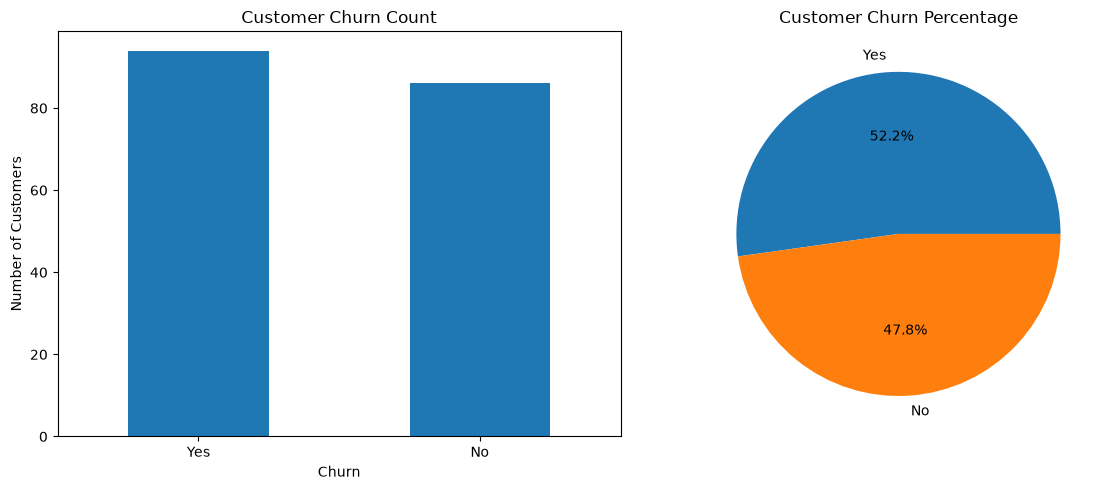

In [304]:
# Inspect the target variable (Churn)

print(df_clean["Churn"].value_counts())

print("---------------------------------------------")

print(
    df_clean["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("---------------------------------------------")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Count plot
df_clean["Churn"].value_counts().plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Customer Churn Count")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Number of Customers")
axes[0].tick_params(axis="x", rotation=0)

# Percentage plot
df_clean["Churn"].value_counts(normalize=True).mul(100).plot(
    kind="pie",
    autopct="%1.1f%%",
    ax=axes[1]
)

axes[1].set_title("Customer Churn Percentage")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

# 4. Exploratory Data Analysis

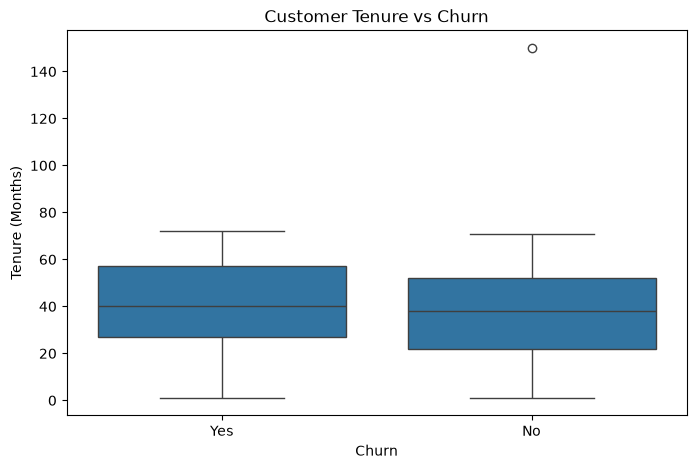

In [305]:
# Tenure distribution by Churn

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="Tenure_Months"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

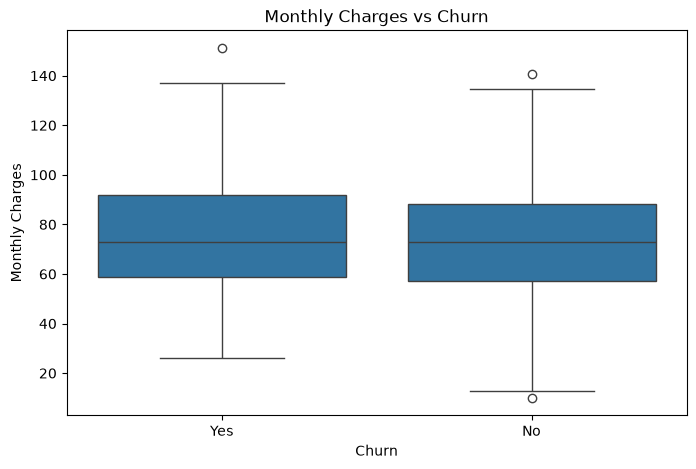

In [306]:
# Monthly Charges vs Churn

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="Monthly_Charges"
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

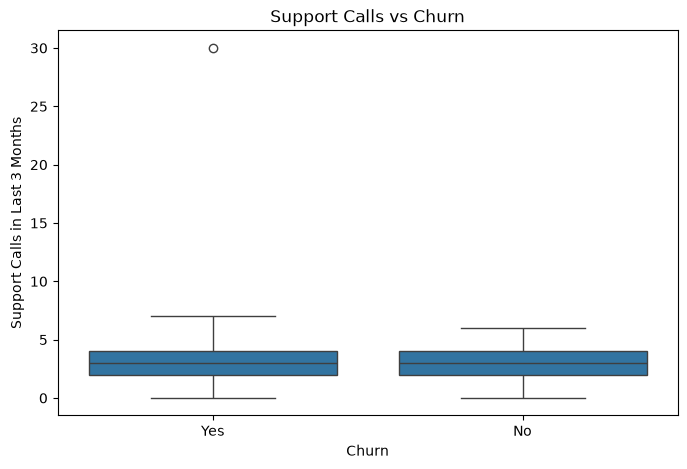

In [307]:
# Support Calls vs Churn

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="Support_Calls_Last_3M"
)

plt.title("Support Calls vs Churn")
plt.xlabel("Churn")
plt.ylabel("Support Calls in Last 3 Months")

plt.show()

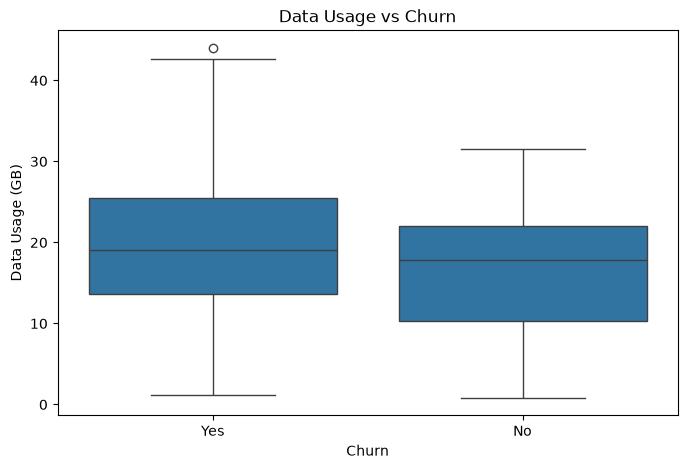

In [308]:
# Data Usage vs Churn

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="Data_Usage_GB"
)

plt.title("Data Usage vs Churn")
plt.xlabel("Churn")
plt.ylabel("Data Usage (GB)")

plt.show()

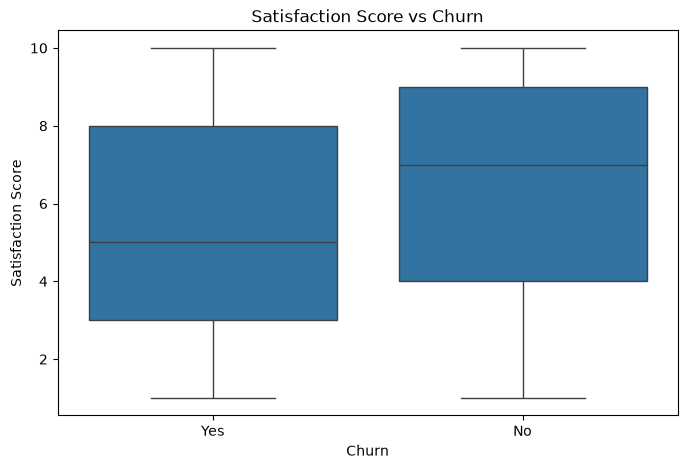

In [309]:
# Satisfaction Score vs Churn

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="Satisfaction_Score"
)

plt.title("Satisfaction Score vs Churn")
plt.xlabel("Churn")
plt.ylabel("Satisfaction Score")

plt.show()

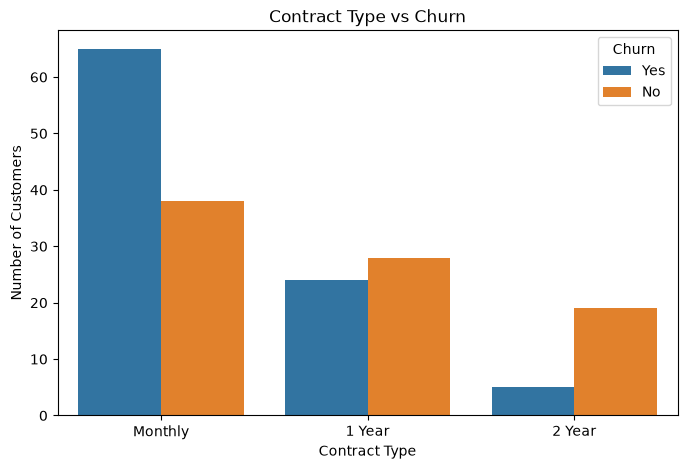

In [310]:
# Contract Type vs Churn

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Contract_Type",
    hue="Churn"
)

plt.title("Contract Type vs Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

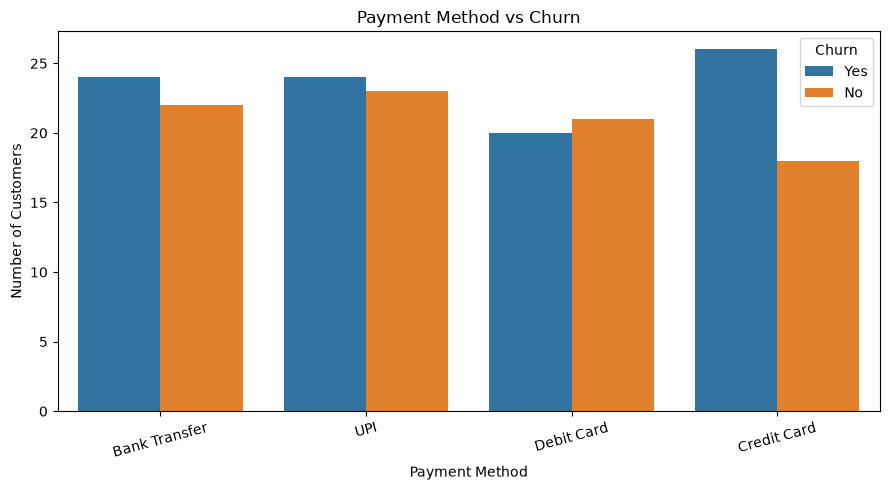

In [311]:
# Payment Method vs Churn

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x="Payment_Method",
    hue="Churn"
)

plt.title("Payment Method vs Churn")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

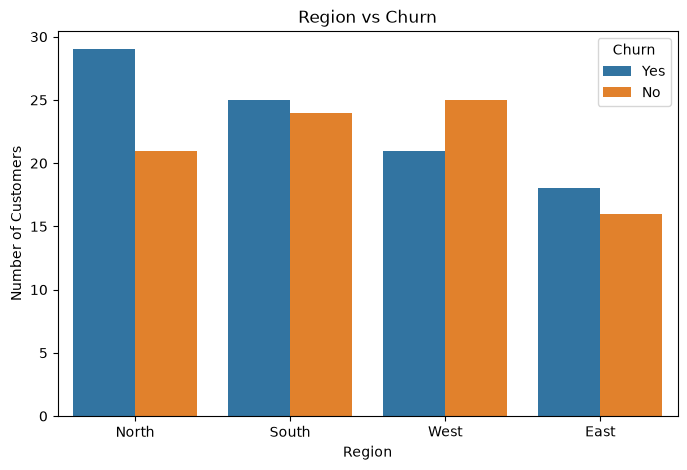

In [312]:
# Region vs Churn

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Region",
    hue="Churn"
)

plt.title("Region vs Churn")
plt.xlabel("Region")
plt.ylabel("Number of Customers")

plt.show()

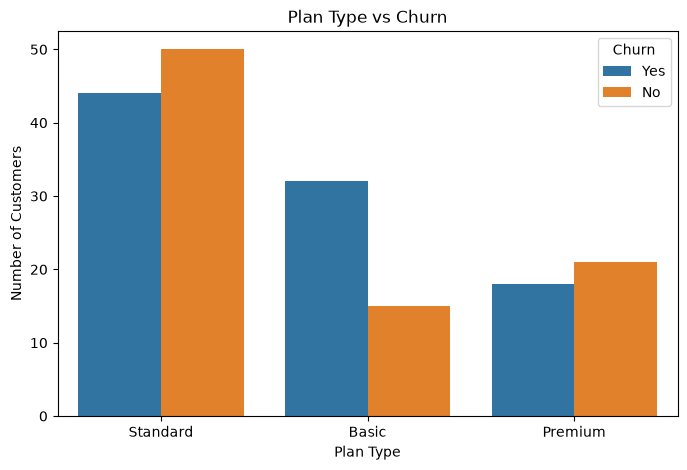

In [313]:
# Plan Type vs Churn

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Plan_Type",
    hue="Churn"
)

plt.title("Plan Type vs Churn")
plt.xlabel("Plan Type")
plt.ylabel("Number of Customers")

plt.show()

In [314]:
# Churn rate within each plan type

plan_churn_rate = pd.crosstab(
    df_clean["Plan_Type"],
    df_clean["Churn"],
    normalize="index"
) * 100

print(plan_churn_rate.round(2))

Churn         No    Yes
Plan_Type              
Basic      31.91  68.09
Premium    53.85  46.15
Standard   53.19  46.81


### Does churn differ by contract type?

In [315]:
# Churn rate by Contract Type

contract_churn_rate = pd.crosstab(
    df_clean["Contract_Type"],
    df_clean["Churn"],
    normalize="index"
) * 100

print(contract_churn_rate.round(2))

Churn             No    Yes
Contract_Type              
1 Year         53.85  46.15
2 Year         79.17  20.83
Monthly        36.89  63.11


In [316]:
# Churn rate by Payment Method

payment_churn_rate = pd.crosstab(
    df_clean["Payment_Method"],
    df_clean["Churn"],
    normalize="index"
) * 100

print(payment_churn_rate.round(2))

Churn              No    Yes
Payment_Method              
Bank Transfer   47.83  52.17
Credit Card     40.91  59.09
Debit Card      51.22  48.78
UPI             48.94  51.06


In [317]:
# Churn rate by Region

region_churn_rate = pd.crosstab(
    df_clean["Region"],
    df_clean["Churn"],
    normalize="index"
) * 100

print(region_churn_rate.round(2))

Churn      No    Yes
Region              
East    47.06  52.94
North   42.00  58.00
South   48.98  51.02
West    54.35  45.65


In [318]:
# Consolidate EDA findings 

# Combine categorical churn rates

categorical_churn_summary = pd.DataFrame({
    "Contract_Type": contract_churn_rate["Yes"],
    "Payment_Method": payment_churn_rate["Yes"],
    "Region": region_churn_rate["Yes"],
    "Plan_Type": plan_churn_rate["Yes"]
})

print(categorical_churn_summary.round(2))

               Contract_Type  Payment_Method  Region  Plan_Type
1 Year                 46.15             NaN     NaN        NaN
2 Year                 20.83             NaN     NaN        NaN
Bank Transfer            NaN           52.17     NaN        NaN
Basic                    NaN             NaN     NaN      68.09
Credit Card              NaN           59.09     NaN        NaN
Debit Card               NaN           48.78     NaN        NaN
East                     NaN             NaN   52.94        NaN
Monthly                63.11             NaN     NaN        NaN
North                    NaN             NaN   58.00        NaN
Premium                  NaN             NaN     NaN      46.15
South                    NaN             NaN   51.02        NaN
Standard                 NaN             NaN     NaN      46.81
UPI                      NaN           51.06     NaN        NaN
West                     NaN             NaN   45.65        NaN


In [319]:
# Create a structured EDA summary

eda_summary = pd.concat([
    contract_churn_rate["Yes"].rename("Churn_Rate").reset_index().assign(
        Feature="Contract_Type"
    ).rename(columns={"Contract_Type": "Category"}),

    payment_churn_rate["Yes"].rename("Churn_Rate").reset_index().assign(
        Feature="Payment_Method"
    ).rename(columns={"Payment_Method": "Category"}),

    region_churn_rate["Yes"].rename("Churn_Rate").reset_index().assign(
        Feature="Region"
    ).rename(columns={"Region": "Category"}),

    plan_churn_rate["Yes"].rename("Churn_Rate").reset_index().assign(
        Feature="Plan_Type"
    ).rename(columns={"Plan_Type": "Category"})
], ignore_index=True)

print(eda_summary.round(2))

         Category  Churn_Rate         Feature
0          1 Year       46.15   Contract_Type
1          2 Year       20.83   Contract_Type
2         Monthly       63.11   Contract_Type
3   Bank Transfer       52.17  Payment_Method
4     Credit Card       59.09  Payment_Method
5      Debit Card       48.78  Payment_Method
6             UPI       51.06  Payment_Method
7            East       52.94          Region
8           North       58.00          Region
9           South       51.02          Region
10           West       45.65          Region
11          Basic       68.09       Plan_Type
12        Premium       46.15       Plan_Type
13       Standard       46.81       Plan_Type


In [320]:
# Separate features and target

X = df_clean.drop(
    columns=["Customer_ID", "Churn"]
)

y = df_clean["Churn"]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

Feature Shape: (180, 11)
Target Shape: (180,)

Feature Columns:
['Age', 'Annual_Income', 'Tenure_Months', 'Monthly_Charges', 'Support_Calls_Last_3M', 'Data_Usage_GB', 'Satisfaction_Score', 'Contract_Type', 'Payment_Method', 'Region', 'Plan_Type']

Target Distribution:
Churn
Yes    94
No     86
Name: count, dtype: int64


# 5. Feature engineering and preprocessing

### Should Customer_ID be used as a feature?

**Decision:** Customer_ID is excluded from the model features.

**Reasoning:**
- Customer_ID is a unique identifier assigned to each customer.
- It does not directly represent customer behavior or characteristics that influence churn.
- Including it may cause the model to learn meaningless patterns based on customer identifiers rather than actual churn-related factors.
- It does not provide meaningful predictive information for new customers.

Therefore, Customer_ID is retained for customer identification and reference purposes but excluded from the independent features (X) used for model training.

In [321]:
%pip install catboost

Note: you may need to restart the kernel to use updated packages.


In [322]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

X = df.drop(columns=["Churn", "Customer_ID"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (147, 11)
Testing: (37, 11)


In [323]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_cols = X_train.select_dtypes(
    include="number"
).columns

categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

X_train_final = preprocessor.fit_transform(X_train)
X_test_final = preprocessor.transform(X_test)

print("Training shape:", X_train_final.shape)
print("Testing shape:", X_test_final.shape)

Training shape: (147, 159)
Testing shape: (37, 159)


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_17840\2531994271.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


### Replacing values for NaN & outliers

In [324]:
# Replace missing categorical values with mode
for col in categorical_cols:
    mode_value = X_train[col].mode()[0]

    X_train[col] = X_train[col].fillna(mode_value)
    X_test[col] = X_test[col].fillna(mode_value)

print("Categorical missing values handled!")

print(X_train[categorical_cols].isnull().sum())
print(X_test[categorical_cols].isnull().sum())

Categorical missing values handled!
Annual_Income     0
Contract_Type     0
Payment_Method    0
Region            0
Plan_Type         0
dtype: int64
Annual_Income     0
Contract_Type     0
Payment_Method    0
Region            0
Plan_Type         0
dtype: int64


In [325]:
# Handle missing values and outliers in numerical columns
for col in numerical_cols:

    # Calculate median using training data
    median_value = X_train[col].median()

    # Calculate IQR using training data
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    # Calculate outlier boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Replace outliers in training data with median
    X_train[col] = X_train[col].mask(
        (X_train[col] < lower_bound) |
        (X_train[col] > upper_bound),
        median_value
    )

    # Replace outliers in testing data using training boundaries
    X_test[col] = X_test[col].mask(
        (X_test[col] < lower_bound) |
        (X_test[col] > upper_bound),
        median_value
    )

    # Replace missing values with training median
    X_train[col] = X_train[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)

print("Numerical missing values and outliers handled!")

print(X_train[numerical_cols].isnull().sum())
print(X_test[numerical_cols].isnull().sum())

Numerical missing values and outliers handled!
Age                      0
Tenure_Months            0
Monthly_Charges          0
Support_Calls_Last_3M    0
Data_Usage_GB            0
Satisfaction_Score       0
dtype: int64
Age                      0
Tenure_Months            0
Monthly_Charges          0
Support_Calls_Last_3M    0
Data_Usage_GB            0
Satisfaction_Score       0
dtype: int64


### Encode categorical variables

In [326]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_encoded = encoder.fit_transform(
    X_train[categorical_cols]
)

X_test_encoded = encoder.transform(
    X_test[categorical_cols]
)

encoded_columns = encoder.get_feature_names_out(
    categorical_cols
)

print("Training:", X_train_encoded.shape)
print("Testing:", X_test_encoded.shape)

Training: (147, 153)
Testing: (37, 153)


### Feature Scaling

In [327]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train[numerical_cols]
)

X_test_scaled = scaler.transform(
    X_test[numerical_cols]
)

print("Training:", X_train_scaled.shape)
print("Testing:", X_test_scaled.shape)

Training: (147, 6)
Testing: (37, 6)


### Combine features

In [328]:
X_train_final = pd.concat([
    pd.DataFrame(
        X_train_scaled,
        columns=numerical_cols,
        index=X_train.index
    ),
    pd.DataFrame(
        X_train_encoded,
        columns=encoded_columns,
        index=X_train.index
    )
], axis=1)

X_test_final = pd.concat([
    pd.DataFrame(
        X_test_scaled,
        columns=numerical_cols,
        index=X_test.index
    ),
    pd.DataFrame(
        X_test_encoded,
        columns=encoded_columns,
        index=X_test.index
    )
], axis=1)

print("Final Training:", X_train_final.shape)
print("Final Testing:", X_test_final.shape)

print("Training NaN:", X_train_final.isnull().sum().sum())
print("Testing NaN:", X_test_final.isnull().sum().sum())

Final Training: (147, 159)
Final Testing: (37, 159)
Training NaN: 0
Testing NaN: 0


### 6. Build multiple supervised learning models

In [329]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "CatBoost": CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        loss_function="Logloss",
        verbose=0,
        random_seed=42,
        thread_count=-1
    )
}

trained_models = {}

for name, model in models.items():

    model.fit(X_train_final, y_train)

    trained_models[name] = model

    print(f"{name} trained successfully")

Logistic Regression trained successfully
KNN trained successfully
Decision Tree trained successfully
Random Forest trained successfully
CatBoost trained successfully


# 8. Cross-validation

In [330]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, pos_label="Yes", zero_division=0
    ),
    "recall": make_scorer(
        recall_score, pos_label="Yes", zero_division=0
    ),
    "f1": make_scorer(
        f1_score, pos_label="Yes", zero_division=0
    )
}

cv_results = []

for name, model in models.items():

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(4))

,Model,CV Accuracy,CV Precision,CV Recall,CV F1
0,Logistic Regression,0.6529,0.6498,0.7142,0.6765
1,KNN,0.4972,0.5169,0.5467,0.5306
2,Decision Tree,0.5379,0.5512,0.6258,0.5846
3,Random Forest,0.6120,0.6082,0.7158,0.6515
4,CatBoost,0.5710,0.5828,0.6642,0.6169


In [331]:
# Tune Random Forest  

from sklearn.metrics import make_scorer, f1_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

f1_yes = make_scorer(
    f1_score,
    pos_label="Yes",
    zero_division=0
)

rf_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

rf_params = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

rf_grid = GridSearchCV(
    rf_pipe,
    rf_params,
    cv=cv,
    scoring=f1_yes,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

rf_grid.fit(X_train, y_train)

print("Best parameters:", rf_grid.best_params_)
print("Best CV F1:", round(rf_grid.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}
Best CV F1: 0.6884


In [332]:
# Tune CatBoost  

from catboost import CatBoostClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

cat_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", CatBoostClassifier(
        loss_function="Logloss",
        verbose=0,
        random_seed=42,
        thread_count=1
    ))
])

cat_params = {
    "classifier__iterations": [200, 300],
    "classifier__depth": [4, 6, 8],
    "classifier__learning_rate": [0.03, 0.1]
}

cat_grid = GridSearchCV(
    cat_pipe,
    cat_params,
    cv=cv,
    scoring=f1_yes,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

cat_grid.fit(X_train, y_train)

print("Best parameters:", cat_grid.best_params_)
print("Best CV F1:", round(cat_grid.best_score_, 4))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters: {'classifier__depth': 4, 'classifier__iterations': 200, 'classifier__learning_rate': 0.03}
Best CV F1: 0.6467


In [333]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

tuned_models = {
    "Tuned Random Forest": rf_grid.best_estimator_,
    "Tuned CatBoost": cat_grid.best_estimator_
}

tuned_results = []

for name, model in tuned_models.items():

    y_pred = model.predict(X_test)

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred,
            pos_label="Yes",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred,
            pos_label="Yes",
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred,
            pos_label="Yes",
            zero_division=0
        )
    })

    print(f"\n{name}")
    print(confusion_matrix(
        y_test, y_pred,
        labels=["No", "Yes"]
    ))

    print(classification_report(
        y_test, y_pred,
        labels=["No", "Yes"],
        zero_division=0
    ))

tuned_results_df = pd.DataFrame(tuned_results)

print("\nTuned Model Comparison:")
display(tuned_results_df.round(4))


Tuned Random Forest
[[ 9  8]
 [ 8 12]]
              precision    recall  f1-score   support

          No       0.53      0.53      0.53        17
         Yes       0.60      0.60      0.60        20

    accuracy                           0.57        37
   macro avg       0.56      0.56      0.56        37
weighted avg       0.57      0.57      0.57        37


Tuned CatBoost
[[ 9  8]
 [ 7 13]]
              precision    recall  f1-score   support

          No       0.56      0.53      0.55        17
         Yes       0.62      0.65      0.63        20

    accuracy                           0.59        37
   macro avg       0.59      0.59      0.59        37
weighted avg       0.59      0.59      0.59        37


Tuned Model Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Tuned Random Forest,0.5676,0.600,0.60,0.6000
1,Tuned CatBoost,0.5946,0.619,0.65,0.6341


# 9. Model comparison

In [334]:
final_comparison = pd.concat(
    [results_df, tuned_results_df],
    ignore_index=True
)

final_comparison = final_comparison.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(final_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,KNN,0.6757,0.7222,0.65,0.6842
1,CatBoost,0.6486,0.6842,0.65,0.6667
2,Decision Tree,0.5946,0.6190,0.65,0.6341
3,Tuned CatBoost,0.5946,0.6190,0.65,0.6341
4,Random Forest,0.5676,0.5909,0.65,0.6190
5,Logistic Regression,0.5676,0.6000,0.60,0.6000
6,Tuned Random Forest,0.5676,0.6000,0.60,0.6000


In [335]:
print(final_comparison.columns.tolist())

['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score']


In [336]:
display(final_comparison)

,Model,Accuracy,Precision,Recall,F1-Score
0,KNN,0.675676,0.722222,0.65,0.684211
1,CatBoost,0.648649,0.684211,0.65,0.666667
2,Decision Tree,0.594595,0.619048,0.65,0.634146
3,Tuned CatBoost,0.594595,0.619048,0.65,0.634146
4,Random Forest,0.567568,0.590909,0.65,0.619048
5,Logistic Regression,0.567568,0.600000,0.60,0.600000
6,Tuned Random Forest,0.567568,0.600000,0.60,0.600000


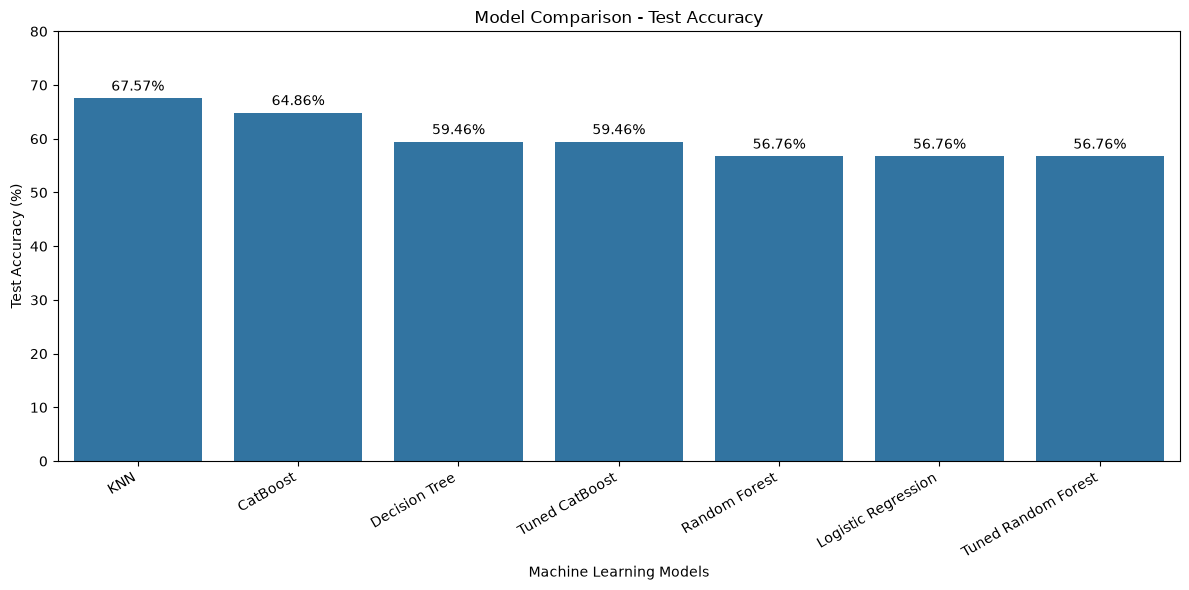

In [337]:
# Convert accuracy into percentage
final_comparison["Accuracy (%)"] = (
    final_comparison["Accuracy"] * 100
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=final_comparison,
    x="Model",
    y="Accuracy (%)"
)

# Display percentages above bars
ax.bar_label(
    ax.containers[0],
    fmt="%.2f%%",
    padding=3
)

plt.title("Model Comparison - Test Accuracy")
plt.xlabel("Machine Learning Models")
plt.ylabel("Test Accuracy (%)")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 80)

plt.tight_layout()
plt.show()

### 10. Final model

Based on the business objective, holdout testing results, and 5-fold cross-validation, we can select ***KNN Classifier*** as the current final candidate model.

### 10.1 Why was this model selected? 

Reasons for selection:

- Selected ***KNN Classifier*** because it achieved the highest test accuracy among the seven evaluated models.

- Achieved 67.57% accuracy, 72.22% precision, 65% recall, and 68.42% F1-score.

- It correctly identified 13 out of 20 actual churn customers in the test dataset.

- KNN had the highest accuracy, precision, and F1-score in the latest comparison table.

### 10.2 Which features appear important? 

(A.) 

KNN does not provide a built-in feature_importances_ attribute like Random Forest. It makes predictions based on distances between customers in the feature space.

To investigate which features influence KNN predictions, use permutation importance with the fitted KNN pipeline.

In [338]:
from sklearn.inspection import permutation_importance
import pandas as pd

# Select trained KNN model
knn_model = trained_models["KNN"]

# Calculate permutation importance
perm_result = permutation_importance(
    knn_model,
    X_test_final,
    y_test,
    scoring="f1_macro",  # Works with "No" and "Yes" labels
    n_repeats=10,
    random_state=42
)

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Create feature importance DataFrame
knn_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": perm_result.importances_mean
})

# Sort features by importance
knn_feature_importance = knn_feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 10 features
display(knn_feature_importance.head(10))

,Feature,Importance
2,num__Monthly_Charges,0.090965
5,num__Satisfaction_Score,0.069105
155,cat__Plan_Type_Premium,0.065925
4,num__Data_Usage_GB,0.063022
147,cat__Region_East,0.057101
154,cat__Plan_Type_Basic,0.047061
1,num__Tenure_Months,0.042071
3,num__Support_Calls_Last_3M,0.028141
109,cat__Annual_Income_76600.0,0.025038
143,cat__Payment_Method_Debit Card,0.024523


### 10.3 What types of errors does the model make?  

KNN confusion matrix, using the latest reported precision and recall and your 20 actual churners:

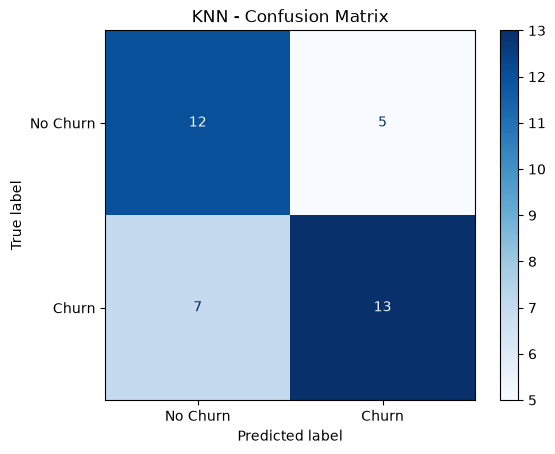

Confusion Matrix:
[[12  5]
 [ 7 13]]


In [339]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate predictions using the trained KNN model
knn_predictions = trained_models["KNN"].predict(X_test_final)

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    knn_predictions,
    labels=["No", "Yes"]
)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("KNN - Confusion Matrix")
plt.show()

# Print matrix values
print("Confusion Matrix:")
print(cm)

 - True Positives: 13 churn customers correctly identified.

 - False Negatives: 7 churn customers incorrectly predicted as non-churn.

 - False Positives: 5 non-churn customers incorrectly predicted as churn.

 - True Negatives: 12 non-churn customers correctly identified.

The model misses 7 actual churners, which may lead to missed retention opportunities. It also flags 5 non-churn customers, which may result in unnecessary retention campaign costs.

### 10.4 How could the business use the predictions?  

 - Identify customers with a high predicted probability of churn.

 - Prioritize retention campaigns for customers at risk of leaving.

 - Provide personalized offers, loyalty benefits, or proactive customer support.

 - Allocate retention budgets based on predicted churn risk and customer value.

 - Monitor actual campaign outcomes and retrain the model as more customer data becomes available.

## Final conclusion

The KNN Classifier is selected as the current final model because it achieved the highest test accuracy (67.57%) and F1-score (68.42%) among the seven models in the latest comparison. It can be used as a pilot churn-risk identification tool, subject to further validation on a larger dataset.

---------------------------------------------------------------------------------------------------------------------------

## 11. Business Recommendations

Below are 5 actionable recommendations for the customer retention team, based on your KNN model results.


### 1. Identify customers at high risk of churn

* Use the KNN model to identify customers predicted to churn.

* Prioritize these customers for personalized offers, follow-up calls, and customer support.

* Focus retention efforts on customers with a high probability of leaving.

### 2. Monitor customer characteristics

* Analyze the top features identified through permutation importance.

* Monitor customer behavior and characteristics associated with churn.

* Use these insights to design targeted retention campaigns.

Note: Mention specific customer segments or features only after reviewing your EDA and feature-importance results.

### 3. Reduce false negatives

* False negatives are actual churners incorrectly predicted as non-churners.

* The retention team may miss opportunities to retain these customers.

* Prioritize improving recall to identify more actual churners.

### 4. Manage false positives

* False positives are customers predicted to churn who actually stay.

* Avoid spending excessive retention resources on every flagged customer.

* Use customer value and campaign cost to prioritize retention offers.

### 5. Improve the model with additional data

* Collect more customer records to improve model reliability.

* Include additional features such as customer complaints, support interactions, payment history, and service usage.

* Regularly evaluate model performance using new customer data before deployment.

### Conclusion

The KNN model achieved the highest test accuracy of 67.57% among the models evaluated in the current comparison, with an F1-score of 68.42%. It can be used as a pilot tool to help the retention team identify potentially at-risk customers. Further validation with a larger dataset is required before using it for real business decisions.


In [340]:
# Save the fully cleaned dataset
df_clean.to_csv(
    "cleaned_customer_churn.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
